# Reading the course images: `ml4eo_data`
**Machine Learning for Earth Observation - every practical uses this**

All practicals read the Sentinel-2 GeoTIFFs in `ml4eo/data/` through one small module, `ml4eo/ml4eo_data.py`. It
1. finds the data folder by itself,
2. reads each `.tiff` (with `rasterio`, or `tifffile` if rasterio is missing) and turns 0 into NaN (no data),
3. turns the coloured scene-classification picture (SCL) back into codes 0-11.

All three dates were exported with the same box and settings, so every file is on **one grid**: 2380 × 1702 pixels of 20 m in UTM zone 36S (EPSG:32736). Pixel (row, col) is the same place on the ground in every band and on every date.

In [1]:
import sys
sys.path.append("..")                      # ml4eo_data.py sits one folder up, in ml4eo/

In [2]:
%run check_environment.py

Python 3.12.14 at c:\Users\user\anaconda3\envs\ml4eo\python.exe
  OK       numpy          2.5.3
  OK       pandas         3.0.6
  OK       matplotlib     3.11.2
  OK       scipy          1.17.1
  OK       scikit-learn   1.9.1
  OK       scikit-image   0.26.0
  OK       rasterio       1.5.0
  OK       geopandas      1.1.3
  OK       shapely        2.1.2
  OK       pyproj         3.7.2
  MISSING  xarray
  MISSING  rioxarray
  OK       jupyterlab     4.6.4

Install the missing packages with:
  conda install -n ml4eo -c conda-forge xarray rioxarray
(Lecture 1 needs only numpy, pandas, matplotlib, scipy, scikit-learn, scikit-image.)

  OK       data folder C:\Users\user\Documents\ML4EO\data
           2026-01-21: 16 files
           2026-05-13: 16 files
           2026-09-03: 16 files
  MISSING  kigali_training_polygons.csv


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from ml4eo_data import (list_files, load_scene, valid_mask, add_indices,
                        load_polygons, pixel_table, as_stack, extent, scl_cmap, save_geotiff, grid, SCL_NAMES, S2_BANDS)

## 1. What is in the data folder?

In [4]:
files = list_files()
files.groupby("date").layer.apply(", ".join)

date
2026-01-21    B01, B02, B03, B04, B05, B06, B07, B08, B09, B...
2026-05-13    B01, B02, B03, B04, B05, B06, B07, B08, B09, B...
2026-09-03    B01, B02, B03, B04, B05, B06, B07, B08, B09, B...
Name: layer, dtype: str

## 2. Load one date
`load_scene` returns a dictionary: one 2-D array per band (reflectance 0-1, `NaN` = no data) plus `"SCL"`.

In [5]:
sep = load_scene("sep")                    # or "2026-09-03"
g = grid()
print("layers:", list(sep))
print("B04 shape:", sep["B04"].shape, sep["B04"].dtype)
print(f"pixel size: {g['dx']:.2f} x {g['dy']:.2f} m, CRS {g['crs']}")

layers: ['B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B8A', 'B09', 'B11', 'B12', 'SCL']
B04 shape: (1702, 2380) float32
pixel size: 19.98 x 19.96 m, CRS EPSG:32736


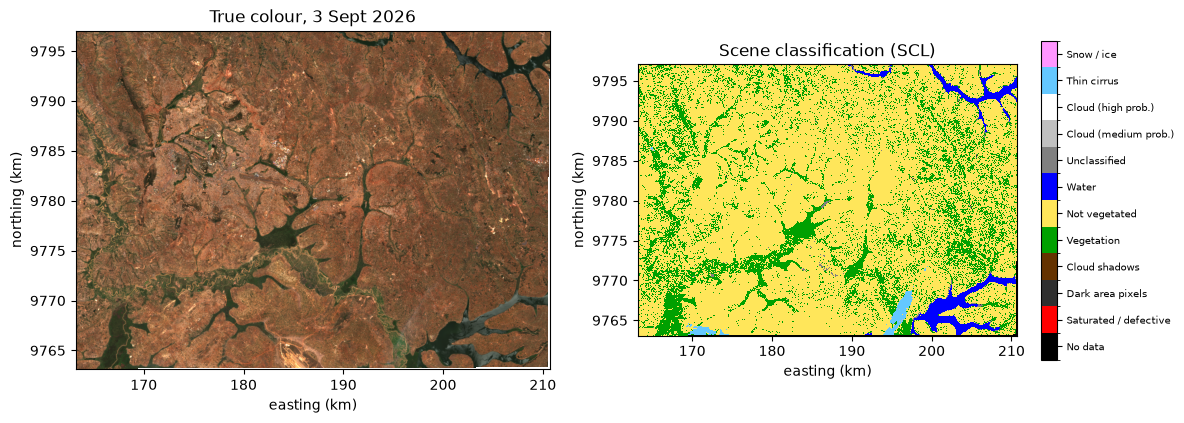

In [6]:
rgb = np.dstack([sep["B04"], sep["B03"], sep["B02"]])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].imshow(np.clip(rgb / 0.25, 0, 1), extent=extent()); ax[0].set_title("True colour, 3 Sept 2026")
cmap, norm = scl_cmap()
im = ax[1].imshow(sep["SCL"], cmap=cmap, norm=norm, interpolation="nearest", extent=extent())
ax[1].set_title("Scene classification (SCL)")
cb = plt.colorbar(im, ax=ax[1], shrink=0.8, ticks=range(12)); cb.ax.set_yticklabels([SCL_NAMES[i] for i in range(12)], fontsize=7)
for a in ax: a.set_xlabel("easting (km)"); a.set_ylabel("northing (km)")
plt.tight_layout(); plt.show()

## 3. Indices and the valid-pixel mask
The NDVI/NDWI `.tiff` files are coloured pictures, not values, so we compute indices from the bands.

In [7]:
add_indices(sep)                           # adds NDVI, NDWI, MNDWI, NDBI
valid = valid_mask(sep)                    # SCL 4, 5 or 6, and every band has data
print(f"valid pixels: {valid.sum():,} of {valid.size:,} ({valid.mean():.1%})")
codes, counts = np.unique(sep["SCL"], return_counts=True)
for c, n in zip(codes, counts): print(f"  SCL {c:2d} {SCL_NAMES[c]:<22} {n:>9,}")

valid pixels: 3,994,419 of 4,050,760 (98.6%)
  SCL  0 No data                   16,081
  SCL  2 Dark area pixels           2,085
  SCL  4 Vegetation               810,677
  SCL  5 Not vegetated          3,088,363
  SCL  6 Water                     95,379
  SCL  7 Unclassified              11,621
  SCL  8 Cloud (medium prob.)         227
  SCL 10 Thin cirrus               26,327


## 4. From images to a feature table
`as_stack` gives the `(bands, rows, cols)` array; `pixel_table` reads values at the labelled pixels.

In [9]:
X_img = as_stack(sep, ["B02", "B03", "B04", "B08", "B11", "B12"])
print("image stack:", X_img.shape)
X_all = X_img[:, valid].T                  # (n_valid_pixels, n_bands): ready for scikit-learn
print("valid-pixel matrix:", X_all.shape)

poly = load_polygons()
tab = pixel_table(sep, poly, ["B04", "B08", "B11", "NDVI", "MNDWI"])
tab.groupby("class")[["NDVI", "MNDWI"]].mean().round(3)

image stack: (6, 1702, 2380)
valid-pixel matrix: (3994419, 6)


,NDVI,MNDWI
class,,
bare soil,0.101,-0.509
built-up,0.081,-0.410
dense vegetation,0.711,-0.509
sparse vegetation,0.446,-0.508
water,-0.160,0.381


## 5. Other dates
January and May have the same 12 bands, on the same grid. Load only the bands you need to save memory (each band is about 16 MB).

In [ ]:
jan = load_scene("jan", ["B04", "B08"]); may = load_scene("may", ["B04", "B08"])
for name, s in [("Jan", jan), ("May", may), ("Sep", sep)]:
    ndvi = (s["B08"] - s["B04"]) / (s["B08"] + s["B04"])
    print(f"{name}: clear pixels (SCL 4/5/6) {np.isin(s['SCL'], [4, 5, 6]).mean():.1%} | median NDVI {np.nanmedian(ndvi):.2f}")

## 6. Saving a map
Any 2-D result on the common grid (a classification, a cluster map) can be written as a GeoTIFF that opens in QGIS.

In [ ]:
ndvi_class = np.where(valid, np.digitize(sep["NDVI"], [0.2, 0.5]) + 1, 0).astype("uint8")
save_geotiff(ndvi_class, "ndvi_classes.tif", nodata=0)
print("written ndvi_classes.tif")

## Replacing the old `.npz` lines in the practicals
| Before | Now |
|---|---|
| `sep = np.load(f"{DATA_DIR}/kigali_sept2026_common_grid.npz")` | `sep = load_scene("sep")` |
| `bands = sep["bands"].astype("float32") / 10000` | `bands = as_stack(sep, S2_BANDS)` (already reflectance) |
| `sep["scl"]` | `sep["SCL"]` |
| `jm["jan_bands"]`, `jm["may_bands"]` | `load_scene("jan")`, `load_scene("may")` (all 12 bands, same grid) |
| `meta["ulx"]`, `meta["dx"]`, ... (degrees) | `grid()["ulx"]`, `grid()["dx"]`, ... (metres, UTM 36S) |
| `pd.read_csv(f"{DATA_DIR}/kigali_training_polygons.csv")` | `load_polygons()` |
| DN 0 = no data | `NaN` = no data (`load_scene(..., scale="dn")` still gives the old integers) |